In [ ]:
from google.colab import files

uploaded = files.upload()

Saving nyayarag_reconstructed_questions.csv to nyayarag_reconstructed_questions.csv


In [ ]:
import pandas as pd

# Change this filename if your uploaded file has a different name
input_file = next(iter(uploaded.keys()))

df = pd.read_csv(input_file)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (10, 14)

Columns:
['Question_ID', 'Experience', 'Visible_Fragment', 'Candidate_1', 'Candidate_1_Word_Count', 'Candidate_2', 'Candidate_2_Word_Count', 'Candidate_3', 'Candidate_3_Word_Count', 'Preferred_Reconstruction', 'Confidence', 'Reasoning', 'Verification_Status', 'Data_Provenance']


,Question_ID,Experience,Visible_Fragment,Candidate_1,Candidate_1_Word_Count,Candidate_2,Candidate_2_Word_Count,Candidate_3,Candidate_3_Word_Count,Preferred_Reconstruction,Confidence,Reasoning,Verification_Status,Data_Provenance
0,RAW001,11–20 years,Under what circumstances can delay in lodging ...,Under what circumstances can delay in lodging ...,13,Under what circumstances can delay in lodging ...,13,Under what circumstances can delay in lodging ...,13,Under what circumstances can delay in lodging ...,Low,"""FIR"" is the usual object of ""lodging"", but ""c...",Inferred,RECONSTRUCTED_NOT_ORIGINAL
1,RAW002,11–20 years,Can a conviction be sustained solely on the te...,Can a conviction be sustained solely on the te...,13,Can a conviction be sustained solely on the te...,13,Can a conviction be sustained solely on the te...,13,Can a conviction be sustained solely on the te...,Medium,"""te"" most plausibly begins ""testimony"". Only 4...",Inferred,RECONSTRUCTED_NOT_ORIGINAL
2,RAW004,11–20 years,When may a court interfere with an arbitral aw...,When may a court interfere with an arbitral aw...,15,When may a court interfere with an arbitral aw...,15,When may a court interfere with an arbitral aw...,15,When may a court interfere with an arbitral aw...,Low,"""aw"" is ""award"". The ground or limit of interf...",Inferred,RECONSTRUCTED_NOT_ORIGINAL
3,RAW005,11–20 years,What are the conditions for granting anticipat...,What are the conditions for granting anticipat...,11,What are the conditions for granting anticipat...,11,What are the conditions for granting anticipat...,11,What are the conditions for granting anticipat...,Medium,"""granting anticipat-"" makes ""anticipatory bail...",Inferred,RECONSTRUCTED_NOT_ORIGINAL
4,RAW006,11–20 years,Under what circumstances can a court permit am...,Under what circumstances can a court permit am...,26,Under what circumstances can a court permit am...,26,Under what circumstances can a court permit am...,26,Under what circumstances can a court permit am...,Very Low,18 of 26 words are missing. What is amended (p...,Ambiguous,RECONSTRUCTED_NOT_ORIGINAL


# **Step 2 — Get a Gemini API key**

In [ ]:
%pip -q install -U google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 18.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [ ]:
from getpass import getpass
from google import genai

API_KEY = getpass("Enter your Gemini API key: ")

client = genai.Client(api_key=API_KEY)

print("Gemini client initialized.")

Enter your Gemini API key: ··········
Gemini client initialized.


In [ ]:
# List all available models
for model in client.models.list():
  print(f"Model ID: {model.name}")
  print(f"Display Name: {model.display_name}")
  print("-" * 40)

Model ID: models/gemini-2.5-flash
Display Name: Gemini 2.5 Flash
----------------------------------------
Model ID: models/gemini-2.5-pro
Display Name: Gemini 2.5 Pro
----------------------------------------
Model ID: models/gemini-2.5-flash-preview-tts
Display Name: Gemini 2.5 Flash Preview TTS
----------------------------------------
Model ID: models/gemini-2.5-pro-preview-tts
Display Name: Gemini 2.5 Pro Preview TTS
----------------------------------------
Model ID: models/gemma-4-26b-a4b-it
Display Name: Gemma 4 26B A4B IT
----------------------------------------
Model ID: models/gemma-4-31b-it
Display Name: Gemma 4 31B IT
----------------------------------------
Model ID: models/gemini-flash-latest
Display Name: Gemini Flash Latest
----------------------------------------
Model ID: models/gemini-flash-lite-latest
Display Name: Gemini Flash-Lite Latest
----------------------------------------
Model ID: models/gemini-pro-latest
Display Name: Gemini Pro Latest
-----------------------

# **Step 3 — Configure the judge**

In [ ]:
# Model ID: models/gemini-pro-latest
# Display Name: Gemini Pro Latest

In [ ]:
MODEL_NAME = "gemini-2.5-flash"

print("Judge model:", MODEL_NAME)

Judge model: gemini-2.5-flash


# **Step 4 — Define the evaluation rubric and prompt**

In [ ]:
import json

EVALUATION_PROMPT = """
You are an expert evaluator of questions generated for NyayaRAG,
a legal question-answering system focused on Indian law.

Evaluate the PREFERRED QUESTION using the supplied row context.

Score each dimension from 0 to 100.

1. Humanization:
   Does it sound naturally written by a real person?
   Assess phrasing, flow, tone, conciseness, and lack of robotic wording.

2. Indian English authenticity:
   Is the wording natural and appropriate for Indian users?
   Consider Indian legal terminology, institutional context, and register.
   Do not reward grammatical errors, forced Hindi expressions,
   stereotypes, or unnecessary Indianisms.

3. Conversational naturalness:
   Would a real user plausibly ask this question in this context?

4. Experience-level alignment:
   Does the vocabulary and complexity fit the supplied experience level?
   Treat experience as context, not a stereotype.

5. Clarity:
   Is the question understandable, focused, and unambiguous?

6. Legal terminology and context:
   Is the terminology appropriate for an Indian legal question?
   Flag questionable legal assumptions. Do not confuse good wording
   with legal correctness.

7. Reconstruction plausibility:
   Does the preferred reconstruction fit the visible fragment and
   available candidates? Penalize unsupported additions.
   The original question is unavailable, so do not claim certainty
   about the original wording.

Important:
- Evaluate the preferred question exactly as written.
- Use the fragment, candidate questions, reasoning, and experience
  level as context.
- Distinguish linguistic quality from reconstruction fidelity.
- A written question cannot establish a spoken accent.
- Do not invent facts or legal conclusions.
- If a dimension cannot be assessed, use null and explain why.
- Return only valid JSON, with no Markdown fences.

Return this schema:
{
  "humanization_score": 0,
  "indian_english_authenticity_score": 0,
  "conversational_naturalness_score": 0,
  "experience_level_alignment_score": 0,
  "clarity_score": 0,
  "legal_terminology_context_score": 0,
  "reconstruction_plausibility_score": 0,
  "overall_quality_score": 0,
  "humanization_reason": "",
  "indian_english_reason": "",
  "experience_level_reason": "",
  "legal_risk_flags": [],
  "unsupported_additions": [],
  "suggested_revision": "",
  "original_question_verifiable": false,
  "evaluation_confidence": "Low"
}

Calculate overall_quality_score using these weights:
Humanization 25%, Indian English authenticity 20%,
conversational naturalness 15%, experience alignment 10%,
clarity 10%, legal terminology/context 10%,
reconstruction plausibility 10%.

If any score is null, set overall_quality_score to null.
All non-null scores must be integers from 0 to 100.

ROW CONTEXT:
{row_context}
"""

# **Step 5 — Evaluate every preferred reconstruction**

In [ ]:
import time
import json
import pandas as pd
from google.genai import types

WEIGHTS = {
    "humanization_score": 0.25,
    "indian_english_authenticity_score": 0.20,
    "conversational_naturalness_score": 0.15,
    "experience_level_alignment_score": 0.10,
    "clarity_score": 0.10,
    "legal_terminology_context_score": 0.10,
    "reconstruction_plausibility_score": 0.10,
}

def safe_text(value):
    if pd.isna(value):
        return ""
    return str(value)

def evaluate_row(row):
    context_columns = [
        "Question_ID",
        "Experience",
        "Visible_Fragment",
        "Candidate_1",
        "Candidate_2",
        "Candidate_3",
        "Preferred_Reconstruction",
        "Confidence",
        "Reasoning",
        "Verification_Status",
        "Data_Provenance",
    ]

    row_context = {
        col: safe_text(row[col])
        for col in context_columns
        if col in row.index
    }

    if not row_context.get("Preferred_Reconstruction", "").strip():
        return {
            "Question_ID": row_context.get("Question_ID", ""),
            "error": "Missing preferred reconstruction",
        }

    # Using .replace to avoid KeyError with curly braces in the schema template
    prompt = EVALUATION_PROMPT.replace(
        "{row_context}", json.dumps(row_context, ensure_ascii=False)
    )

    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config=types.GenerateContentConfig(
                    response_mime_type="application/json",
                    temperature=0,
                ),
            )

            result = json.loads(response.text)

            # Validate score fields and calculate the weighted score ourselves.
            scores = []
            valid = True

            for field, weight in WEIGHTS.items():
                value = result.get(field)

                if value is None:
                    valid = False
                    continue

                if isinstance(value, bool) or not isinstance(value, (int, float)):
                    raise ValueError(f"Invalid score type for {field}")

                if not 0 <= value <= 100:
                    raise ValueError(f"Out-of-range score for {field}")

                scores.append((value, weight))

            if valid:
                result["overall_quality_score"] = round(
                    sum(value * weight for value, weight in scores)
                )
            else:
                result["overall_quality_score"] = None

            result["Question_ID"] = row_context.get("Question_ID", "")
            result["Evaluated_Question"] = row_context.get(
                "Preferred_Reconstruction", ""
            )
            result["judge_model"] = MODEL_NAME
            result["error"] = ""

            return result

        except Exception as exc:
            if attempt == 2:
                return {
                    "Question_ID": row_context.get("Question_ID", ""),
                    "Evaluated_Question": row_context.get(
                        "Preferred_Reconstruction", ""
                    ),
                    "judge_model": MODEL_NAME,
                    "error": str(exc)[:500],
                }

            time.sleep(2 ** attempt)

results = []

for i, (_, row) in enumerate(df.iterrows(), start=1):
    result = evaluate_row(row)
    results.append(result)

    print(
        f"Processed {i}/{len(df)} | "
        f"{result.get('Question_ID', 'Unknown')} | "
        f"Overall: {result.get('overall_quality_score', 'N/A')} | "
        f"Error: {result.get('error', '') or 'None'}"
    )

    # Small delay to reduce the chance of hitting request limits.
    time.sleep(1)

scores_df = pd.DataFrame(results)

print("\nEvaluation completed.")
display(scores_df.head())


Processed 1/10 | RAW001 | Overall: 91 | Error: None
Processed 2/10 | RAW002 | Overall: 98 | Error: None
Processed 3/10 | RAW004 | Overall: 94 | Error: None
Processed 4/10 | RAW005 | Overall: 94 | Error: None
Processed 5/10 | RAW006 | Overall: 95 | Error: None
Processed 6/10 | RAW007 | Overall: 89 | Error: None
Processed 7/10 | RAW010 | Overall: 90 | Error: None
Processed 8/10 | RAW012 | Overall: 94 | Error: None
Processed 9/10 | RAW015 | Overall: 88 | Error: None
Processed 10/10 | RAW017 | Overall: 96 | Error: None

Evaluation completed.


,humanization_score,indian_english_authenticity_score,conversational_naturalness_score,experience_level_alignment_score,clarity_score,legal_terminology_context_score,reconstruction_plausibility_score,overall_quality_score,humanization_reason,indian_english_reason,experience_level_reason,legal_risk_flags,unsupported_additions,suggested_revision,original_question_verifiable,evaluation_confidence,Question_ID,Evaluated_Question,judge_model,error
0,90,95,85,95,95,95,80,91,The question is phrased naturally and concisel...,The phrase 'lodging an FIR' is standard and au...,The question uses precise legal terminology ('...,[],[],,False,High,RAW001,Under what circumstances can delay in lodging ...,gemini-2.5-flash,
1,98,98,98,98,98,98,98,98,The question is phrased naturally and directly...,The wording 'Can a conviction be sustained sol...,The question uses precise legal terminology ('...,[],[],,False,High,RAW002,Can a conviction be sustained solely on the te...,gemini-2.5-flash,
2,95,95,90,95,95,95,90,94,The question is phrased naturally and professi...,"The terminology 'arbitral award', 'interfere',...",The phrase 'limited supervisory jurisdiction' ...,[],[],,False,High,RAW004,When may a court interfere with an arbitral aw...,gemini-2.5-flash,
3,95,95,90,90,95,100,90,94,The question is phrased naturally and directly...,The terms 'anticipatory bail' and 'accused' ar...,"Given an experience level of '11–20 years', th...",[],[],,False,High,RAW005,What are the conditions for granting anticipat...,gemini-2.5-flash,
4,95,98,90,98,98,99,85,95,The question is formally phrased and sounds li...,The question uses standard legal terminology a...,"The question's vocabulary and complexity, part...",[],"[of pleadings after the commencement of trial,...",,False,High,RAW006,Under what circumstances can a court permit am...,gemini-2.5-flash,


# Step 6 — Save the evaluation results to CSV

In [ ]:
output_file = "nyayarag_llm_judge_evaluation.csv"

scores_df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("Saved:", output_file)
print("Successful evaluations:", (scores_df["error"] == "").sum())
print("Failed evaluations:", (scores_df["error"] != "").sum())

from google.colab import files
files.download(output_file)

Saved: nyayarag_llm_judge_evaluation.csv
Successful evaluations: 10
Failed evaluations: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Step 7 — Analyze the results**

Successful rows: 10

Metric summary:


,count,mean,std,min,25%,50%,75%,max
humanization_score,10.0,93.3,3.80,85.0,91.25,95.0,95.00,98.0
indian_english_authenticity_score,10.0,96.4,1.90,95.0,95.00,95.0,98.00,100.0
conversational_naturalness_score,10.0,90.1,4.98,80.0,90.00,90.0,92.25,98.0
experience_level_alignment_score,10.0,95.8,2.70,90.0,95.00,95.0,97.75,100.0
clarity_score,10.0,96.7,1.89,95.0,95.00,96.5,98.00,100.0
legal_terminology_context_score,10.0,97.8,2.10,95.0,95.75,98.0,99.75,100.0
reconstruction_plausibility_score,10.0,76.3,28.79,20.0,81.25,90.0,90.00,98.0
overall_quality_score,10.0,92.9,3.25,88.0,90.25,94.0,94.75,98.0


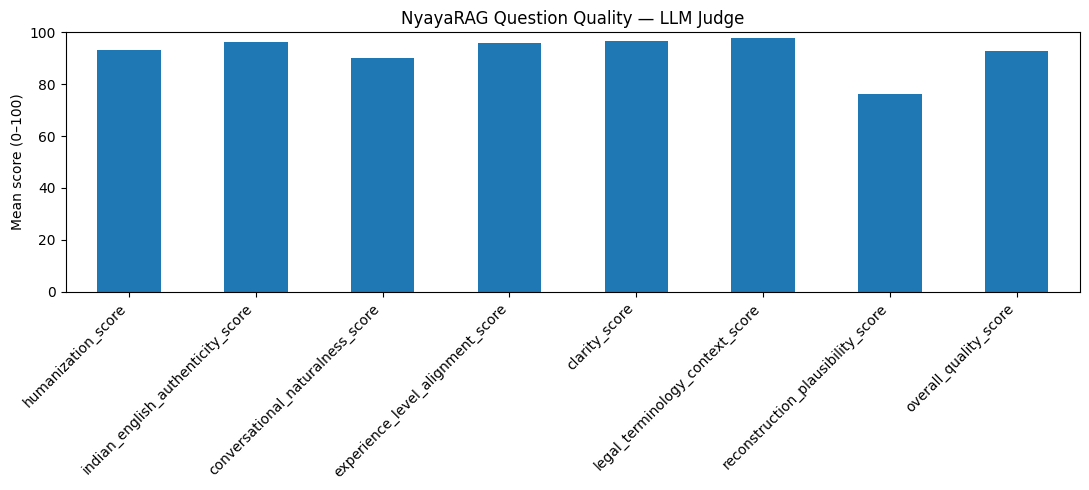

In [ ]:
import matplotlib.pyplot as plt

metric_columns = [
    "humanization_score",
    "indian_english_authenticity_score",
    "conversational_naturalness_score",
    "experience_level_alignment_score",
    "clarity_score",
    "legal_terminology_context_score",
    "reconstruction_plausibility_score",
    "overall_quality_score",
]

# Convert score columns to numeric in case of unexpected output types.
for col in metric_columns:
    if col in scores_df.columns:
        scores_df[col] = pd.to_numeric(scores_df[col], errors="coerce")

successful = scores_df[
    scores_df["error"].fillna("").eq("")
].copy()

print("Successful rows:", len(successful))
print("\nMetric summary:")
display(
    successful[metric_columns]
    .describe()
    .round(2)
    .T
)

# Average score per metric
means = successful[metric_columns].mean().dropna()

plt.figure(figsize=(11, 5))
means.plot(kind="bar")
plt.ylim(0, 100)
plt.ylabel("Mean score (0–100)")
plt.title("NyayaRAG Question Quality — LLM Judge")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# **Step 8 — Identify questions that need manual review**

In [ ]:
review = successful.copy()

review["Needs_Review"] = (
    (review["overall_quality_score"] < 75)
    | (review["indian_english_authenticity_score"] < 75)
    | (review["reconstruction_plausibility_score"] < 75)
    | (review["evaluation_confidence"] == "Low")
    | review["legal_risk_flags"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    )
)

review_columns = [
    "Question_ID",
    "Evaluated_Question",
    "humanization_score",
    "indian_english_authenticity_score",
    "reconstruction_plausibility_score",
    "overall_quality_score",
    "evaluation_confidence",
    "legal_risk_flags",
    "suggested_revision",
    "Needs_Review",
]

display(
    review[review_columns]
    .sort_values("overall_quality_score", na_position="first")
)

review.to_csv(
    "nyayarag_questions_for_manual_review.csv",
    index=False,
    encoding="utf-8-sig",
)

,Question_ID,Evaluated_Question,humanization_score,indian_english_authenticity_score,reconstruction_plausibility_score,overall_quality_score,evaluation_confidence,legal_risk_flags,suggested_revision,Needs_Review
8,RAW015,How can a magistrate certify the correctness o...,90,100,20,88,Low,[],,True
5,RAW007,What are the essential ingredients required to...,95,98,25,89,Low,[],,True
6,RAW010,What are the mandatory preconditions for exerc...,85,95,90,90,High,[],,False
0,RAW001,Under what circumstances can delay in lodging ...,90,95,80,91,High,[],,False
7,RAW012,Can a civil suit for damages on account of mur...,95,95,90,94,High,[],,False
3,RAW005,What are the conditions for granting anticipat...,95,95,90,94,High,[],,False
2,RAW004,When may a court interfere with an arbitral aw...,95,95,90,94,High,[],,False
4,RAW006,Under what circumstances can a court permit am...,95,98,85,95,High,[],,False
9,RAW017,Can an authorised signatory be convicted under...,95,95,95,96,High,[],,False
1,RAW002,Can a conviction be sustained solely on the te...,98,98,98,98,High,[],,False


# **Step 9 — Optional: compare all three candidates**

In [ ]:
candidate_rows = []

for _, row in df.iterrows():
    for candidate_col in ["Candidate_1", "Candidate_2", "Candidate_3"]:
        if candidate_col not in df.columns:
            continue

        candidate = safe_text(row[candidate_col]).strip()
        if not candidate:
            continue

        modified = row.copy()
        modified["Preferred_Reconstruction"] = candidate

        result = evaluate_row(modified)
        result["Candidate_Name"] = candidate_col
        result["Is_Preferred"] = (
            candidate == safe_text(row.get("Preferred_Reconstruction")).strip()
        )

        candidate_rows.append(result)

candidate_scores = pd.DataFrame(candidate_rows)

candidate_scores.to_csv(
    "nyayarag_candidate_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

display(
    candidate_scores[
        [
            "Question_ID",
            "Candidate_Name",
            "Is_Preferred",
            "humanization_score",
            "indian_english_authenticity_score",
            "reconstruction_plausibility_score",
            "overall_quality_score",
            "error",
        ]
    ]
)

files.download("nyayarag_candidate_comparison.csv")

,Question_ID,Candidate_Name,Is_Preferred,humanization_score,indian_english_authenticity_score,reconstruction_plausibility_score,overall_quality_score,error
0,RAW001,Candidate_1,True,90.0,95.0,80.0,91.0,
1,RAW001,Candidate_2,False,90.0,95.0,80.0,92.0,
2,RAW001,Candidate_3,False,95.0,95.0,95.0,95.0,
3,RAW002,Candidate_1,True,95.0,95.0,95.0,95.0,
4,RAW002,Candidate_2,False,95.0,95.0,95.0,96.0,
5,RAW002,Candidate_3,False,90.0,95.0,90.0,92.0,
6,RAW004,Candidate_1,False,NaN,NaN,NaN,NaN,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...
7,RAW004,Candidate_2,True,NaN,NaN,NaN,NaN,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...
8,RAW004,Candidate_3,False,95.0,95.0,40.0,90.0,
9,RAW005,Candidate_1,True,95.0,95.0,95.0,95.0,


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>